# Prédire la notation de crédit avec une forêt aléatoire

**Projet de classe — une méthode, un résultat principal.**

Objectif : prédire la catégorie de crédit d'une entreprise à partir de ses ratios financiers, avec un classifieur Random Forest constitué d'arbres de décision. Le notebook couvre le nettoyage, l'exploration, l'entraînement et l'évaluation sur des entreprises jamais vues à l'entraînement.

La cible est regroupée en sept catégories ordonnées : `AAA`, `AA`, `A`, `BBB`, `BB`, `B`, `CCC/below`. Les ratios financiers sont les seuls prédicteurs. Le score ESG est laissé de côté : il s'agit d'une photographie actuelle rapprochée de notations historiques (2010–2016), avec une couverture incomplète.

**Résultat principal :** l'exactitude sur le jeu de test, calculée plus bas. Le F1 macro, l'exactitude équilibrée et la proportion de prédictions à un bucket près complètent l'interprétation du déséquilibre et de l'ordre des classes.

## Méthode et détails mathématiques

### Un arbre de décision : choisir une partition

À un nœud contenant un ensemble d'observations $S$, l'impureté de Gini mesure le mélange des classes :

$$G(S)=1-\sum_{k=1}^{K}p_k^2,$$

où $p_k$ est la proportion d'observations de la classe $k$ dans $S$. Un nœud pur a une impureté nulle. Pour une division en enfants gauche et droit, le gain de Gini est :

$$\Delta G=G(S)-\frac{n_L}{n}G(S_L)-\frac{n_R}{n}G(S_R),$$

avec $n=n_L+n_R$. L'arbre choisit la variable et le seuil qui maximisent ce gain, puis répète l'opération dans ses feuilles jusqu'aux contraintes d'arrêt.

### Forêt aléatoire : agréger des arbres diversifiés

Une forêt entraîne $B$ arbres sur des échantillons bootstrap : chaque arbre reçoit un tirage avec remise des observations d'entraînement. À chaque nœud, il n'examine qu'un sous-ensemble aléatoire des variables (`max_features='sqrt'`). Ces deux sources d'aléa rendent les arbres moins corrélés.

Pour une observation $x$, chaque arbre $b$ fournit une probabilité de classe $\hat p_b(k\mid x)$. La forêt moyenne ces probabilités :

$$\hat p(k\mid x)=\frac{1}{B}\sum_{b=1}^{B}\hat p_b(k\mid x),\qquad \hat y(x)=\operatorname*{argmax}_{k}\hat p(k\mid x).$$

La moyenne réduit la variance d'un arbre isolé et les divisions successives captent des non-linéarités et des interactions entre ratios. `class_weight='balanced_subsample'` rééquilibre les classes dans chaque bootstrap ; `min_samples_leaf=2` évite les feuilles à une seule observation.

### Ce que la méthode ne garantit pas

Le modèle traite les sept catégories comme des classes, sans imposer leur ordre. Une erreur `AAA` vers `AA` coûte donc autant à l'exactitude qu'une erreur `AAA` vers `CCC/below`. Le taux de prédictions à un bucket près est ajouté comme lecture ordinale complémentaire. Le split par entreprise limite la fuite liée aux observations répétées d'un ticker, mais ne constitue pas une validation temporelle. Enfin, les résultats sont prédictifs et ne démontrent pas de causalité.

## 1. Chargement et aperçu des données

Le fichier financier contient une observation par action de notation d'entreprise. Les ratios candidats couvrent liquidité, endettement, marges, rentabilité, efficacité et flux de trésorerie. On charge les CSV locaux pour que le notebook soit reproductible hors ligne.

In [33]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    RandomizedSearchCV,
    StratifiedGroupKFold,
)
from sklearn.pipeline import make_pipeline

plt.style.use('seaborn-v0_8-whitegrid')

ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / 'data' / 'ccrd_financial_raw.csv').exists()),
    Path.cwd(),
)
DATA_PATH = ROOT / 'data' / 'ccrd_financial_raw.csv'
raw = pd.read_csv(DATA_PATH)

print(f'Fichier : {DATA_PATH}')
print(f'Dimensions : {raw.shape[0]:,} lignes × {raw.shape[1]} colonnes')
display(raw.head())

Fichier : c:\Users\Lewis\ClaudeCode\AXA\credit_notation\data\ccrd_financial_raw.csv
Dimensions : 5,403 lignes × 25 colonnes


,Rating Agency,Corporation,Rating,Rating Date,CIK,Binary Rating,SIC Code,Sector,Ticker,Current Ratio,...,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share
0,Standard & Poor's Ratings Services,american-states-water-co,A-,2010,1056903,1,4941,Utils,AWR,1.1507,...,28.9834,13.6093,8.3224,0.3173,8.1724,8.1978,2.6385,4.4530,1.9957,-0.1333
1,Standard & Poor's Ratings Services,automatic-data-processing-inc,AAA,2010,8670,1,7374,BusEq,ADP,1.1129,...,23.9379,20.8699,13.5690,0.3324,22.0354,47.2858,4.4944,21.8765,0.2501,0.3132
2,Standard & Poor's Ratings Services,avnet-inc,BBB-,2010,8858,1,5065,Shops,AVT,1.9276,...,3.6338,3.0536,2.1418,2.4620,13.6376,16.7991,5.2731,9.6494,-7.6079,-7.3231
3,Standard & Poor's Ratings Services,california-water-service-co,AA-,2010,1035201,1,4941,Utils,CWT,0.8358,...,27.9377,15.1135,9.0246,0.2946,9.6412,9.7015,2.6583,5.1018,1.7438,-0.8999
4,Standard & Poor's Ratings Services,cardinal-health-inc,A,2010,721371,1,5122,Shops,CAH,1.2931,...,1.5847,1.2304,0.6518,4.9276,11.1256,19.4184,2.9364,8.1844,1.9725,2.4174


faisons un brief diagnostic de la base de donnée 

In [3]:
FEATURES = [
    'Current Ratio',
    'Long-term Debt / Capital',
    'Debt/Equity Ratio',
    'Gross Margin',
    'Operating Margin',
    'EBIT Margin',
    'EBITDA Margin',
    'Pre-Tax Profit Margin',
    'Net Profit Margin',
    'Asset Turnover',
    'ROE - Return On Equity',
    'ROA - Return On Assets',
    'ROI - Return On Investment',
    'Operating Cash Flow Per Share',
    'Free Cash Flow Per Share',
]

print('Types des colonnes :')
display(raw.dtypes.value_counts().rename_axis('type').to_frame('nombre de colonnes'))
print('Valeurs manquantes dans les variables candidates :')
display(raw[FEATURES + ['Ticker', 'Rating']].isna().sum().sort_values(ascending=False).to_frame('valeurs manquantes'))
print(f"Tickers distincts : {raw['Ticker'].nunique():,}")
print(f"Ratings bruts distincts : {raw['Rating'].nunique()}")
display(raw['Rating'].value_counts().rename_axis('Rating').to_frame('effectif'))

Types des colonnes :


,nombre de colonnes
type,
float64,16
str,5
int64,4


Valeurs manquantes dans les variables candidates :


,valeurs manquantes
Current Ratio,0
Long-term Debt / Capital,0
Debt/Equity Ratio,0
Gross Margin,0
Operating Margin,0
EBIT Margin,0
EBITDA Margin,0
Pre-Tax Profit Margin,0
Net Profit Margin,0
Asset Turnover,0


Tickers distincts : 678
Ratings bruts distincts : 22


,effectif
Rating,
BBB,628
BBB+,578
A,556
BBB-,517
A-,453
BB+,370
BB-,347
BB,343
B+,315


## Que représentent les 15 ratios financiers ?

Les ratios résument cinq dimensions de la santé financière. Les formules ci-dessous sont les définitions usuelles ; les conventions exactes (moyenne ou valeur de fin d'année, dette retenue, nombre d'actions) peuvent varier selon la source des données.

| Dimension | Ratio | Lecture économique |
|---|---|---|
| Liquidité | `Current Ratio` | Actifs courants / passifs courants ; capacité à couvrir les échéances de court terme. |
| Endettement | `Long-term Debt / Capital` | Dette à long terme rapportée au capital (dette à long terme + capitaux propres) ; part du financement portée par la dette. |
| Endettement | `Debt/Equity Ratio` | Dette rapportée aux capitaux propres ; levier financier et exposition au remboursement. |
| Marges | `Gross Margin` | (Chiffre d'affaires − coût des ventes) / chiffre d'affaires ; rentabilité après coûts directs. |
| Marges | `Operating Margin` | Résultat opérationnel / chiffre d'affaires ; rentabilité de l'activité courante. |
| Marges | `EBIT Margin` | EBIT / chiffre d'affaires ; rentabilité avant intérêts et impôts. |
| Marges | `EBITDA Margin` | EBITDA / chiffre d'affaires ; rentabilité opérationnelle avant intérêts, impôts, amortissements. |
| Marges | `Pre-Tax Profit Margin` | Résultat avant impôt / chiffre d'affaires. |
| Marges | `Net Profit Margin` | Résultat net / chiffre d'affaires ; part du chiffre d'affaires qui devient bénéfice net. |
| Efficacité | `Asset Turnover` | Chiffre d'affaires rapporté aux actifs ; capacité des actifs à générer des ventes. |
| Rendement | `ROE - Return On Equity` | Résultat net rapporté aux capitaux propres ; rendement pour les actionnaires. |
| Rendement | `ROA - Return On Assets` | Résultat net rapporté aux actifs ; rentabilité des ressources détenues. |
| Rendement | `ROI - Return On Investment` | Rendement généré par le capital investi ; la définition précise dépend de la source. |
| Trésorerie | `Operating Cash Flow Per Share` | Flux de trésorerie opérationnel par action ; liquidités générées par l'activité pour chaque action. |
| Trésorerie | `Free Cash Flow Per Share` | Flux opérationnel moins investissements, rapporté par action ; trésorerie restant après les dépenses d'investissement. |

En général, davantage de liquidité, de marges et de flux de trésorerie est favorable, tandis qu'un levier élevé accroît le risque financier. Ce ne sont pas des lois universelles : les secteurs diffèrent, et plusieurs ratios de marge partagent des composantes comptables, donc ils sont corrélés.

### Diagnostic initial et regroupement de la cible

La base contient 5 403 observations, 678 entreprises et 22 libellés de notation. Les effectifs sont très inégaux : plusieurs catégories du bas de l'échelle comptent très peu d'observations (par exemple `CC+` n'apparaît qu'une fois, `C` huit fois et `CCC-` dix fois). Une forêt à 22 classes devrait estimer une probabilité pour chacune d'elles, alors que certaines classes seraient presque absentes de nombreux nœuds et échantillons bootstrap.

Pour une classe `k`, l'impureté de Gini d'un nœud est $G=1-\sum_{k=1}^{K}p_k^2$. Quand une classe est rare, sa proportion $p_k$ et le gain de Gini associé à une division peuvent être estimés de façon instable. Les arbres risquent alors de ne jamais prédire certaines classes, ou de les apprendre à partir de quelques observations seulement. Le problème est amplifié par le déséquilibre ; une pondération des classes peut aider, mais ne crée pas de nouvelles observations.

Regrouper les notations définit une nouvelle cible $Y^*=g(Y)$. Le modèle estime alors $P(Y^*=j\mid X)$, c'est-à-dire la somme des probabilités des notations brutes réunies dans le groupe. Cela réduit la sparsité et rend l'apprentissage des groupes plus stable, mais fait perdre l'information `+`/`-` et la possibilité de distinguer chaque notch. En classification standard, une erreur est en outre évaluée par $\mathbf{1}_{Y^*\ne\widehat{Y^*}}$ : une erreur d'un seul bucket coûte autant qu'une erreur de plusieurs buckets. Nous conservons donc aussi une mesure « à un bucket près ».

**Choix pour ce projet :** passer des 22 ratings bruts à 7 catégories ordonnées pour obtenir des classes moins rares et une cible encore interprétable.

## 2. Nettoyage et construction de la cible

Les suffixes `+` et `-` sont regroupés au niveau de leur famille de rating. Les catégories `CCC` et inférieures sont fusionnées parce que les ratings extrêmes sont peu nombreux. Les libellés non reconnus sont affichés et provoquent une erreur plutôt que d'être supprimés silencieusement. Les valeurs infinies deviennent manquantes ; les lignes incomplètes sur les prédicteurs, le ticker ou la cible sont ensuite écartées.

l'objectif est de passer de 22 classes cibles, à juste 7 classes 

In [16]:
BUCKET_ORDER = ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC/below']
RATING_TO_BUCKET = {
    'AAA': 'AAA',
    'AA+': 'AA', 'AA': 'AA', 'AA-': 'AA',
    'A+': 'A', 'A': 'A', 'A-': 'A',
    'BBB+': 'BBB', 'BBB': 'BBB', 'BBB-': 'BBB',
    'BB+': 'BB', 'BB': 'BB', 'BB-': 'BB',
    'B+': 'B', 'B': 'B', 'B-': 'B',
    'CCC+': 'CCC/below', 'CCC': 'CCC/below', 'CCC-': 'CCC/below',
    'CC+': 'CCC/below', 'CC': 'CCC/below', 'C': 'CCC/below',
    'D': 'CCC/below', 'RD': 'CCC/below', 'SD': 'CCC/below',
}

data = raw.copy()
data['Rating'] = data['Rating'].astype('string').str.strip().str.upper()
data['rating_bucket'] = data['Rating'].map(RATING_TO_BUCKET)
unknown_ratings = sorted(data.loc[data['rating_bucket'].isna(), 'Rating'].dropna().unique())
print('Ratings sans correspondance :', unknown_ratings if unknown_ratings else 'aucun')
if unknown_ratings:
    raise ValueError(f'Compléter RATING_TO_BUCKET avant de continuer : {unknown_ratings}')

# detecter si il ya des valeurs problématiques, et si oui les remplacer par NA
infinite_count = int(np.isinf(data[FEATURES].to_numpy(dtype=float)).sum())
data[FEATURES] = data[FEATURES].replace([np.inf, -np.inf], np.nan)
duplicate_count = int(data.duplicated().sum()) # verification si il ya des duplicats 
data = data.drop_duplicates() # on enlève les duplicates si il y en as 
missing_rows = int(data[FEATURES + ['Ticker', 'rating_bucket']].isna().any(axis=1).sum())
data = data.dropna(subset=FEATURES + ['Ticker', 'rating_bucket']).copy()
data['rating_bucket'] = pd.Categorical(
    data['rating_bucket'], categories=BUCKET_ORDER, ordered=True
)

print(f'Valeurs infinies remplacées : {infinite_count}')
print(f'Lignes dupliquées exactes retirées : {duplicate_count}')
print(f'Lignes incomplètes retirées : {missing_rows}')
print(f'Dimensions après nettoyage : {data.shape[0]:,} × {data.shape[1]}')
display(data['rating_bucket'].value_counts(sort=False).rename_axis('catégorie').to_frame('effectif'))

Ratings sans correspondance : aucun
Valeurs infinies remplacées : 0
Lignes dupliquées exactes retirées : 0
Lignes incomplètes retirées : 0
Dimensions après nettoyage : 5,403 × 26


,effectif
catégorie,
AAA,71
AA,300
A,1274
BBB,1723
BB,1060
B,778
CCC/below,197


- aucunes lignes dupliques 
- on passe de 22 classes de ratings à 7 classes 

## 3. Exploration des données

On examine le déséquilibre de la cible et les distributions/corrélations des ratios. Les corrélations signalent les variables qui évoluent ensemble ; elles ne prouvent pas qu'une variable cause une notation.



In [20]:
display(data[FEATURES].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Current Ratio,5403.0,1.931,1.906,0.175,1.077,1.512,2.180,34.077
Long-term Debt / Capital,5403.0,0.466,2.914,-86.364,0.286,0.428,0.547,171.500
Debt/Equity Ratio,5403.0,-0.225,39.198,-1473.098,0.413,0.758,1.218,194.375
Gross Margin,5403.0,42.098,23.832,-87.684,22.060,39.073,59.361,100.000
Operating Margin,5403.0,11.191,26.123,-461.788,5.856,11.935,19.127,93.993
EBIT Margin,5403.0,11.241,26.136,-461.788,5.902,11.986,19.170,93.993
EBITDA Margin,5403.0,19.757,25.083,-360.817,10.676,18.182,30.447,286.494
Pre-Tax Profit Margin,5403.0,8.266,28.270,-476.010,3.622,9.469,16.250,221.289
Net Profit Margin,5403.0,5.625,24.600,-414.825,2.443,6.763,12.018,219.390
Asset Turnover,5403.0,0.863,0.707,0.068,0.403,0.668,1.053,8.504


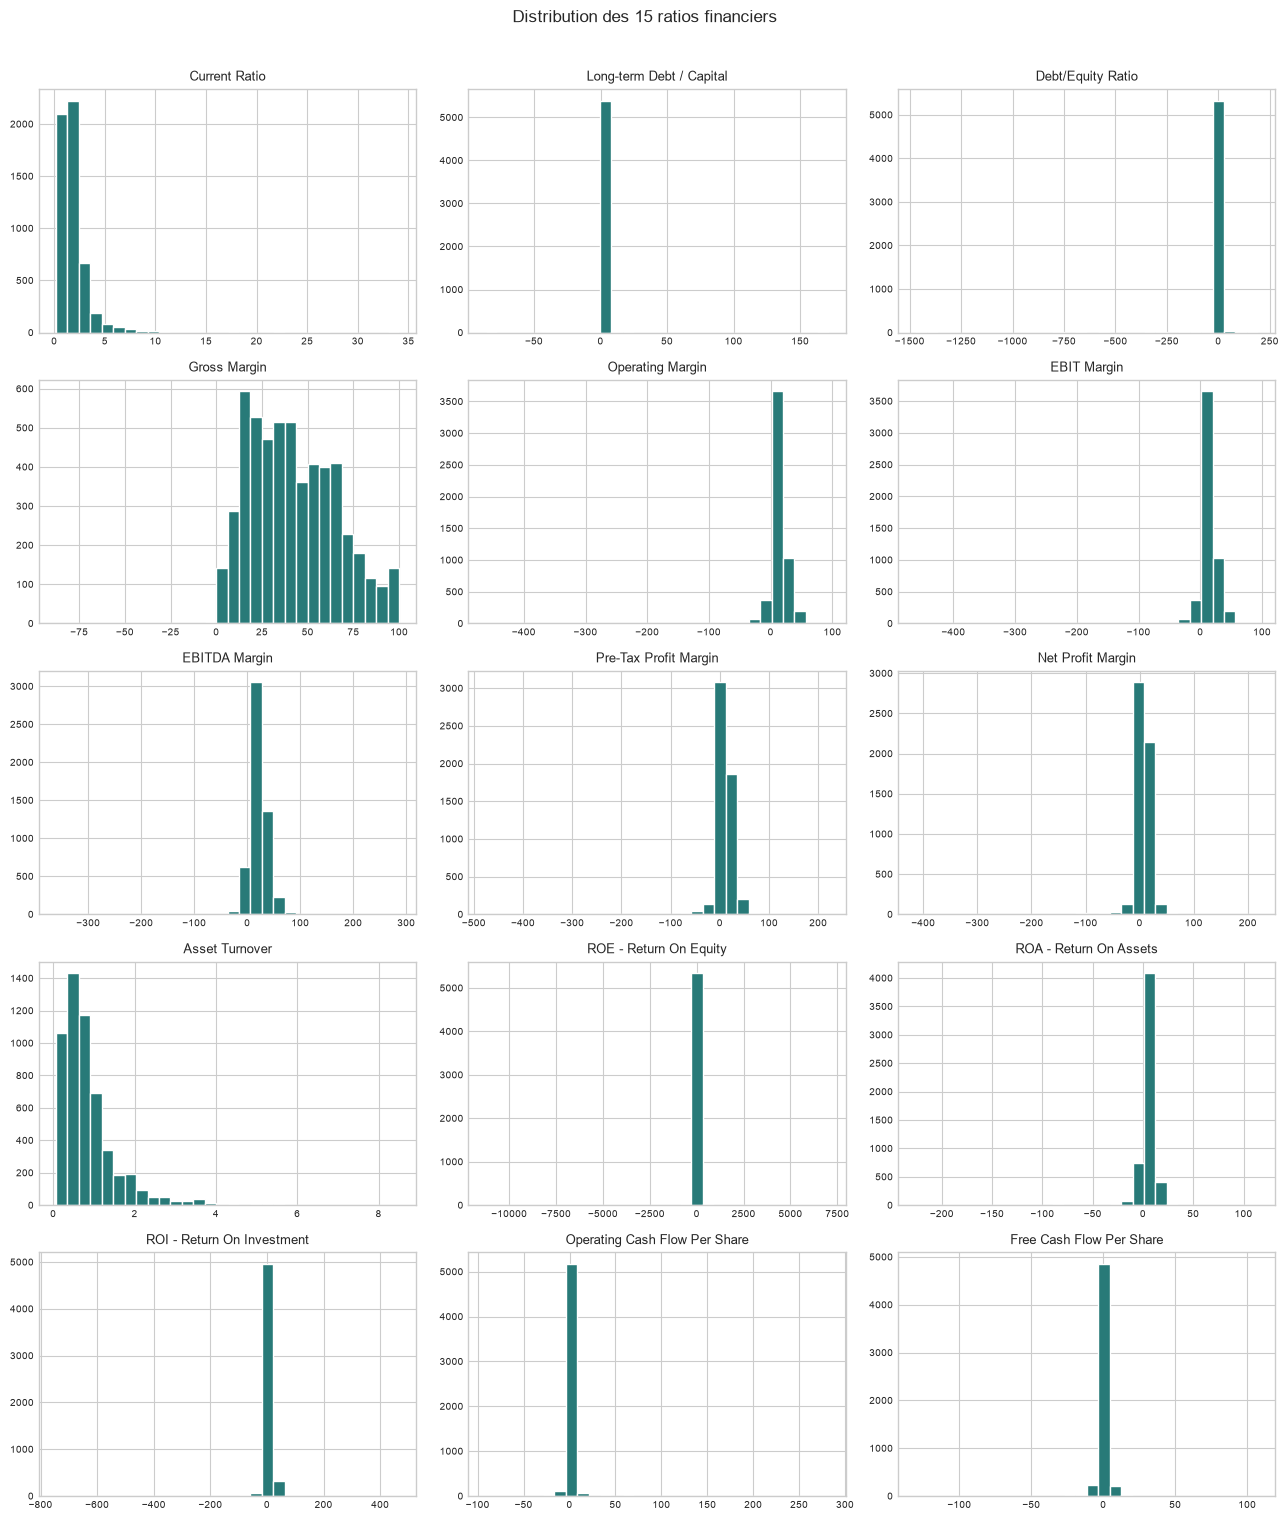

In [30]:
fig, axes = plt.subplots(5, 3, figsize=(13, 15))
for feature, ax in zip(FEATURES, axes.flat):
    ax.hist(data[feature].dropna(), bins=30, color='#287a78', edgecolor='white')
    ax.set_title(feature, fontsize=9)
    ax.tick_params(axis='both', labelsize=7)
fig.suptitle('Distribution des 15 ratios financiers', y=1.01)
fig.tight_layout()
plt.show()

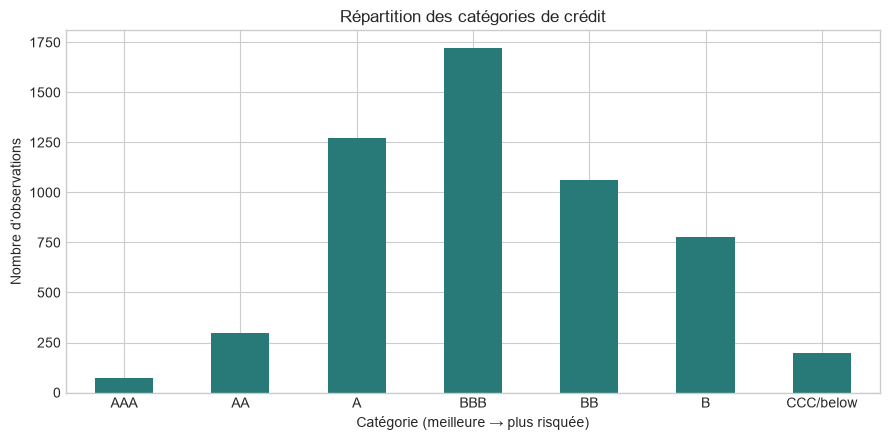

In [21]:


fig, ax = plt.subplots(figsize=(9, 4.5))
data['rating_bucket'].value_counts(sort=False).plot(kind='bar', ax=ax, color='#287a78')
ax.set(title='Répartition des catégories de crédit', xlabel='Catégorie (meilleure → plus risquée)', ylabel='Nombre d’observations')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
plt.show()

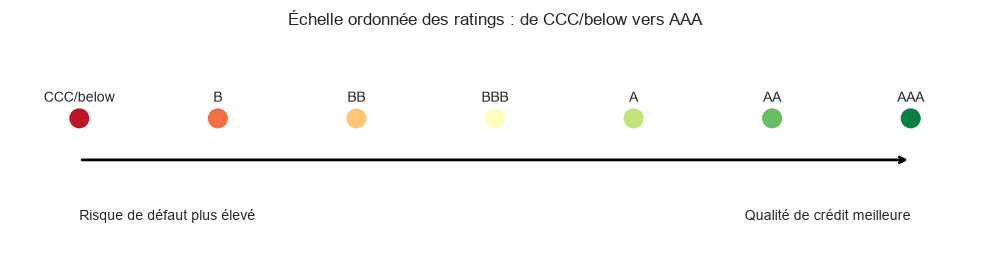

In [31]:
rating_scale = list(reversed(BUCKET_ORDER))
positions = np.arange(len(rating_scale))
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.scatter(
    positions,
    np.zeros(len(positions)),
    c=plt.cm.RdYlGn(np.linspace(0.05, 0.95, len(positions))),
    s=180,
    zorder=2,
)
for position, rating in zip(positions, rating_scale):
    ax.annotate(rating, (position, 0), xytext=(0, 12), textcoords='offset points', ha='center')
ax.annotate('', xy=(6, -0.22), xytext=(0, -0.22), arrowprops={'arrowstyle': '->', 'lw': 2})
ax.text(0, -0.48, 'Risque de défaut plus élevé', ha='left', va='top')
ax.text(6, -0.48, 'Qualité de crédit meilleure', ha='right', va='top')
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(-0.75, 0.45)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('Échelle ordonnée des ratings : de CCC/below vers AAA')
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
plt.show()

### Corrélations entre ratios et avec la cible

La carte suivante résume les corrélations de Pearson entre les ratios financiers. Une corrélation mesure une association linéaire : pour deux variables $X$ et $Z$, $r_{XZ}=\operatorname{Cov}(X,Z)/(s_Xs_Z)$. Elle varie entre -1 et 1 ; elle ne mesure ni une causalité ni une association non linéaire.

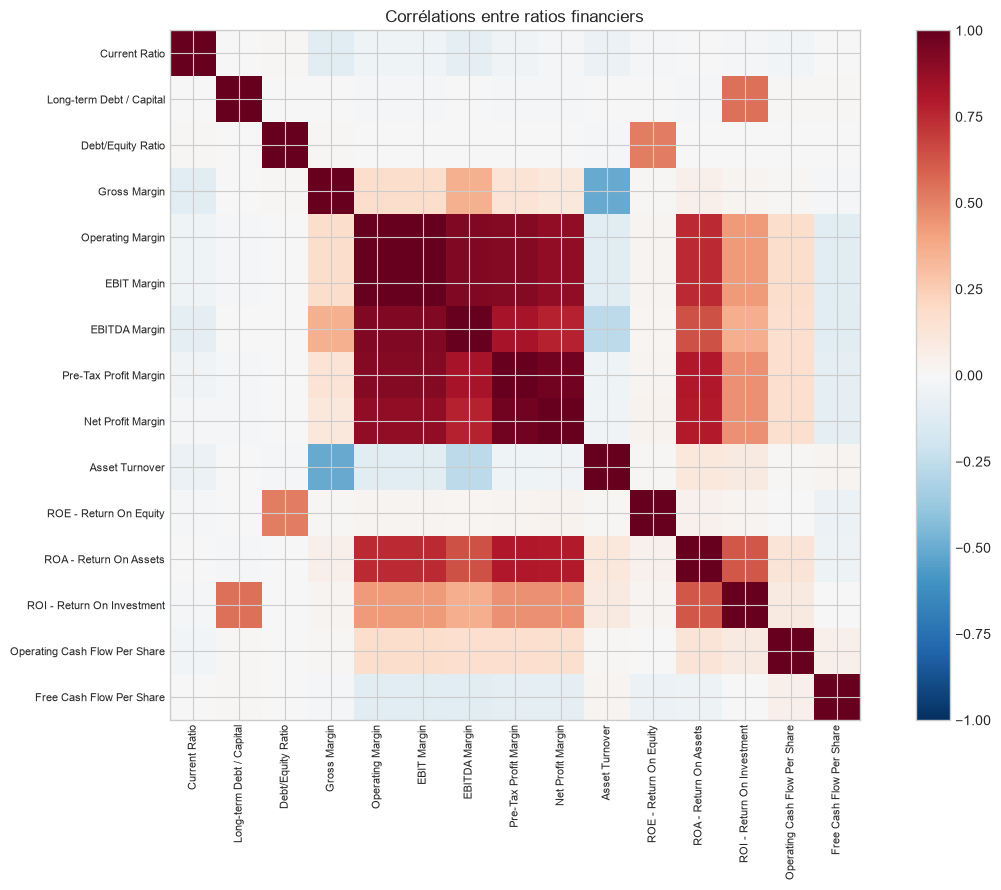

In [22]:
correlation = data[FEATURES].corr()
fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90, fontsize=8)
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(FEATURES, fontsize=8)
ax.set_title('Corrélations entre ratios financiers')
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

### Association monotone entre chaque ratio et la notation

Pour la cible, une corrélation de Pearson traiterait les catégories comme des nombres à intervalles égaux, hypothèse peu justifiée. On utilise donc la corrélation de Spearman entre chaque ratio et le rang ordinal de la notation (`AAA = 0`, ..., `CCC/below = 6`). Elle mesure une association monotone à partir des rangs. Une valeur positive signifie ici que le ratio tend à augmenter quand la qualité de crédit se dégrade ; une valeur négative indique l'association inverse.

Cette visualisation est descriptive, calculée pour comprendre les données. Elle n'est utilisée ni pour sélectionner les variables ni pour régler le modèle ; elle n'établit pas de relation causale.

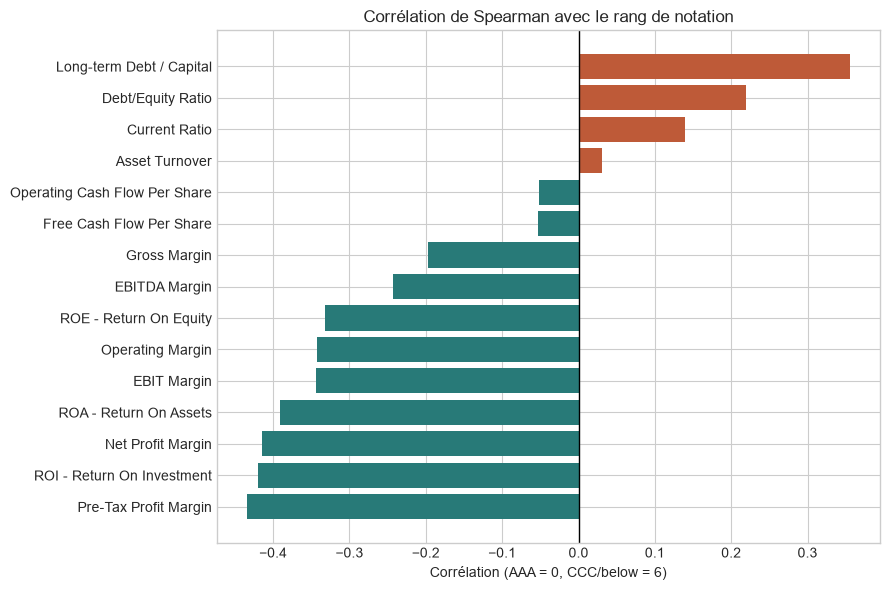

,Spearman rho
Pre-Tax Profit Margin,-0.434235
ROI - Return On Investment,-0.419464
Net Profit Margin,-0.414280
ROA - Return On Assets,-0.390580
EBIT Margin,-0.344046
Operating Margin,-0.341924
ROE - Return On Equity,-0.332060
EBITDA Margin,-0.242676
Gross Margin,-0.196796
Free Cash Flow Per Share,-0.052918


In [32]:
rating_rank = data['rating_bucket'].cat.codes
spearman_to_rating = data[FEATURES].corrwith(rating_rank, method='spearman').sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#287a78' if value < 0 else '#be5a38' for value in spearman_to_rating]
ax.barh(spearman_to_rating.index, spearman_to_rating.values, color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set(
    title='Corrélation de Spearman avec le rang de notation',
    xlabel='Corrélation (AAA = 0, CCC/below = 6)',
)
fig.tight_layout()
plt.show()
display(spearman_to_rating.rename('Spearman rho').to_frame())

## 4. Séparation entraînement / test par entreprise

Les lignes d'une même entreprise peuvent se répéter dans le temps. Un split aléatoire par ligne risquerait donc de placer un ticker dans les deux jeux. `GroupShuffleSplit` réserve 25 % des groupes ; l'imputation sera ajustée uniquement pendant le `fit` sur l'entraînement grâce au pipeline.

In [23]:
X = data[FEATURES]
y = data['rating_bucket'].astype(str)
groups = data['Ticker'].astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

overlap = set(groups_train) & set(groups_test)
assert not overlap, f'Fuite de tickers détectée : {len(overlap)}'
assert set(BUCKET_ORDER).issubset(set(y_train)), 'Une catégorie manque dans le jeu d’entraînement.'

print(f'Entraînement : {len(X_train):,} lignes, {groups_train.nunique():,} tickers')
print(f'Test : {len(X_test):,} lignes, {groups_test.nunique():,} tickers')
print(f'Tickers partagés : {len(overlap)}')
display(pd.concat([y_train.value_counts().reindex(BUCKET_ORDER), y_test.value_counts().reindex(BUCKET_ORDER)], axis=1, keys=['train', 'test']).fillna(0).astype(int))

Entraînement : 3,966 lignes, 508 tickers
Test : 1,437 lignes, 170 tickers
Tickers partagés : 0


,train,test
rating_bucket,,
AAA,49,22
AA,233,67
A,987,287
BBB,1293,430
BB,746,314
B,521,257
CCC/below,137,60


## 5. Modèle : forêt aléatoire de classification

### D'un arbre CART à une forêt

Un arbre CART partitionne récursivement l'espace des ratios. Dans un nœud $C$, si $p_{Ck}$ est la proportion de la classe $k$, son impureté de Gini est

$$G(C)=\sum_{k=1}^{K}p_{Ck}(1-p_{Ck})=1-\sum_{k=1}^{K}p_{Ck}^{2}.$$

Pour une coupure candidate qui crée $C_L$ et $C_R$, l'arbre cherche un grand gain d'impureté :

$$\Delta G=G(C)-\frac{n_L}{n_C}G(C_L)-\frac{n_R}{n_C}G(C_R).$$

Une coupure est intéressante si les nœuds enfants sont plus homogènes en notation que le parent. L'arbre répète ce choix jusqu'aux contraintes de profondeur et de taille minimale des feuilles.

Une forêt aléatoire ajoute deux aléas, comme dans le cours :

1. **Bootstrap des observations** : chaque arbre est ajusté sur un échantillon de taille $n$ tiré avec remise parmi les $n$ observations d'entraînement. Environ $(1-1/n)^n\approx e^{-1}\approx 36,8\%$ des observations ne sont pas tirées pour un arbre donné ; elles constituent son échantillon out-of-bag.
2. **Sous-échantillonnage des variables** : à chaque nœud, seule une partie aléatoire des ratios est candidate à la coupure. Ici `max_features='sqrt'` correspond à environ $\sqrt{15}$ variables candidates par nœud.

Ces deux sources d'aléa diversifient les arbres. Pour une classe $k$, la forêt moyenne les probabilités estimées par ses $B$ arbres, puis prédit la classe de probabilité moyenne maximale :

$$\widehat p_k(x)=\frac{1}{B}\sum_{b=1}^{B}\widehat p_{bk}(x),\qquad \widehat y(x)=\operatorname*{argmax}_{k}\widehat p_k(x).$$

La méthode capture des seuils, non-linéarités et interactions sans standardiser les ratios. `class_weight='balanced_subsample'` compense le déséquilibre à l'intérieur de chaque bootstrap ; `min_samples_leaf` et `max_depth` contrôlent la complexité des arbres. Les catégories sont néanmoins traitées comme nominales : la forêt ne sait pas qu'une erreur `AAA → AA` est moins éloignée qu'une erreur `AAA → CCC/below`.

### Réglage et évaluation

Pour améliorer le modèle sans choisir les paramètres sur le test, nous comparons plusieurs configurations de **la même forêt** par validation croisée stratifiée et groupée par ticker. Le critère de réglage est le F1 macro, qui accorde le même poids aux sept catégories. La forêt retenue est ensuite évaluée une seule fois sur le jeu de test par ticker ; l'exactitude reste le résultat principal, complété par le F1 macro et la distance en buckets.

**Référence du cours :** `slides_apprentissage_2026.pdf`, diapos 43 (indice de Gini), 47–50 (bootstrap, forêts, OOB), 51 (paramètres) et 52–54 (importance des variables). Référence citée dans les diapositives : Breiman et al. (1984), *Classification and Regression Trees*.

In [27]:
base_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    ),
)

parameter_distributions = {
    'randomforestclassifier__max_features': ['sqrt', 0.7, None],
    'randomforestclassifier__min_samples_leaf': [2, 5, 10],
    'randomforestclassifier__max_depth': [None, 10, 20],
    'randomforestclassifier__class_weight': [None, 'balanced_subsample'],
}
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=parameter_distributions,
    n_iter=8,
    scoring='f1_macro',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)
search.fit(X_train, y_train, groups=groups_train)
model = search.best_estimator_

print('Meilleurs paramètres :', search.best_params_)
print(f'F1 macro moyen en validation croisée groupée : {search.best_score_:.3f}')
print('Les tickers du test n’ont pas participé au réglage.')

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
bucket_code = {label: index for index, label in enumerate(BUCKET_ORDER)}
within_one = np.mean([
    abs(bucket_code[actual] - bucket_code[predicted]) <= 1
    for actual, predicted in zip(y_test, y_pred)
])

print(f'RÉSULTAT PRINCIPAL — exactitude test : {accuracy:.3f} ({accuracy:.1%})')
print(f'F1 macro test : {macro_f1:.3f}')
print(f'Exactitude équilibrée test : {balanced_accuracy:.3f}')
print(f'Prédictions à un bucket près : {within_one:.1%}')

Meilleurs paramètres : {'randomforestclassifier__min_samples_leaf': 2, 'randomforestclassifier__max_features': 0.7, 'randomforestclassifier__max_depth': 20, 'randomforestclassifier__class_weight': 'balanced_subsample'}
F1 macro moyen en validation croisée groupée : 0.273
Les tickers du test n’ont pas participé au réglage.
RÉSULTAT PRINCIPAL — exactitude test : 0.363 (36.3%)
F1 macro test : 0.253
Exactitude équilibrée test : 0.254
Prédictions à un bucket près : 84.2%


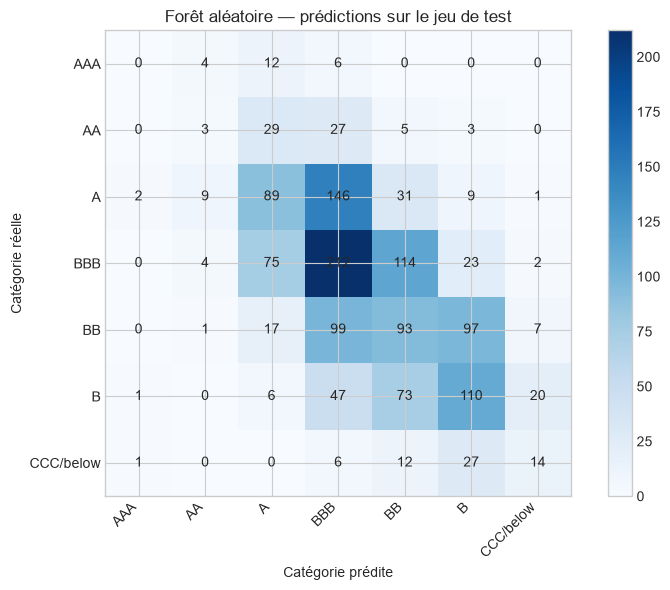

In [25]:
cm = confusion_matrix(y_test, y_pred, labels=BUCKET_ORDER)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(BUCKET_ORDER)))
ax.set_xticklabels(BUCKET_ORDER, rotation=45, ha='right')
ax.set_yticks(range(len(BUCKET_ORDER)))
ax.set_yticklabels(BUCKET_ORDER)
for row in range(len(BUCKET_ORDER)):
    for column in range(len(BUCKET_ORDER)):
        ax.text(column, row, cm[row, column], ha='center', va='center')
ax.set(title='Forêt aléatoire — prédictions sur le jeu de test', xlabel='Catégorie prédite', ylabel='Catégorie réelle')
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

## 6. Conclusion et limites

La recherche aléatoire, évaluée par validation croisée stratifiée et groupée par ticker, retient une forêt avec `max_features=0.7`, `min_samples_leaf=2`, `max_depth=20` et `class_weight='balanced_subsample'`. Son F1 macro moyen en validation croisée est **0,273**. Sur le test initial, composé d'entreprises absentes de l'entraînement, l'exactitude est **36,3 %**, le F1 macro **0,253**, et **84,2 %** des prédictions sont à un bucket près.

La performance exacte reste modeste. Le F1 macro indique que les classes minoritaires demeurent difficiles à prédire ; le taux à un bucket près est plus encourageant. Le split par entreprise évite de partager un ticker entre train et test, mais ne constitue pas une validation temporelle ou externe. Une validation plus forte nécessiterait des ratings et ratios issus d'une source indépendante et datés de façon cohérente.